In [1]:
# Run this cell before the panel cells.
from pathlib import Path
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image as PILImage

# Set BASE to the folder containing these notebooks.
BASE = Path.cwd()
DATA_DIR = BASE / "data"
PROJECT_ROOT = Path(os.environ.get("TOMTOM_PROJECT_ROOT", str(BASE / "source_data")))
OUTPUT_ROOT = BASE / "figures" / "fig2"
USE_SAVED_MAPS = True

def show_saved(path):
    with PILImage.open(path) as image:
        image = image.convert("RGB")
        width, height = image.size
        fig, ax = plt.subplots(figsize=(9, 9 * height / width))
        ax.imshow(image)
        ax.axis("off")
        fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
        plt.show()
        plt.close(fig)


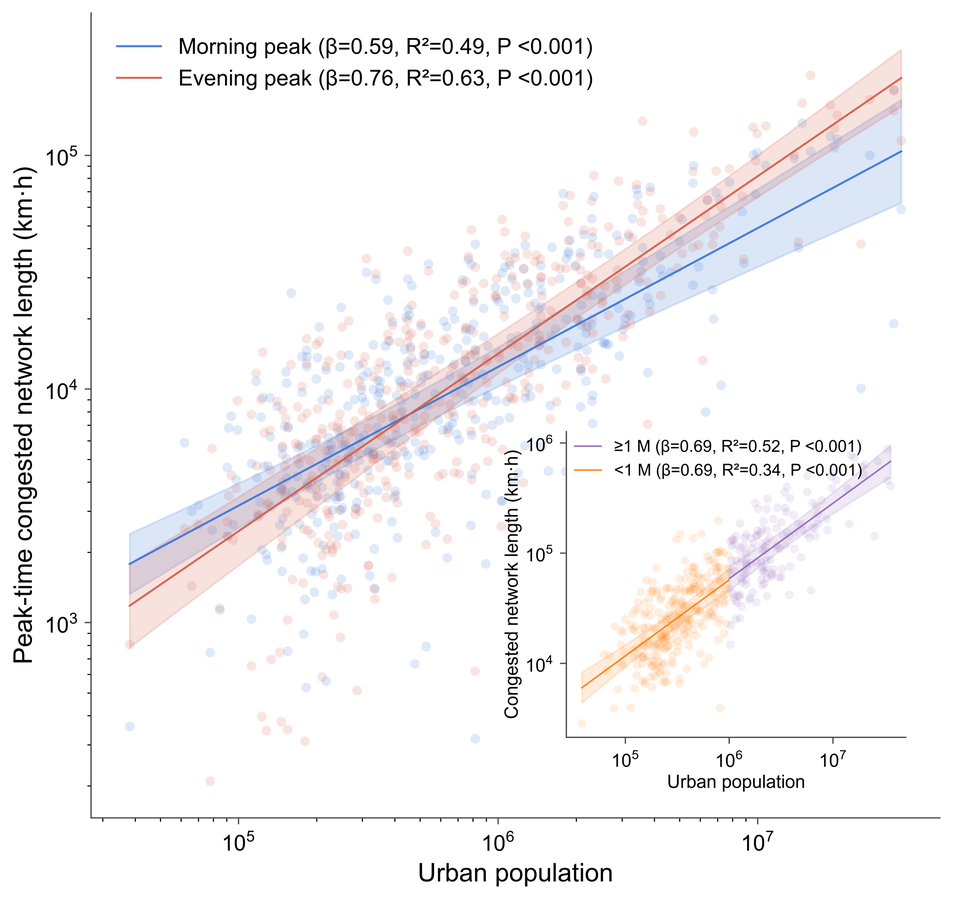

In [2]:
# Panel a: Annual peak regressions and inset
def annual_peaks(data_dir, project_root, output_dir):

    output_dir.mkdir(parents=True, exist_ok=True)
    import warnings
    from pathlib import Path

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import matplotlib.ticker as ticker
    import statsmodels.api as sm
    from scipy.stats import t
    from mpl_toolkits.axes_grid1.inset_locator import inset_axes

    FILE_PATH = data_dir / "city_annual.csv"

    OUT_DIR = output_dir
    OUT_DIR.mkdir(parents=True, exist_ok=True)

    FIGSIZE_MAIN = (7.4, 7.0)
    DPI_FIG      = 140
    DPI_SAVE     = 600

    SCATTER_SIZE  = 28
    SCATTER_ALPHA = 0.18
    LINE_WIDTH    = 1.1
    LINE_ALPHA    = 0.95
    CI_ALPHA      = 0.20
    CI_LEVEL      = 0.05

    FONT_SIZE     = 12

    COLOR_MORNING = "#3c78d8"
    COLOR_EVENING = "#d6604d"

    COLOR_BIG = "tab:purple"
    COLOR_SML = "tab:orange"

    POP_THRESHOLD = 1_000_000

    SPINE_COLOR = "#4A4A4A"
    SPINE_LW    = 0.7

    INSET_BBOX = (0.56, 0.10, 0.40, 0.38)



    CITY_COL         = "city"
    POP_COL          = "population"
    METRIC_ALLDAY    = "congested_network_length"
    METRIC_MORNING   = "morning_peak_congested_network_length"
    METRIC_EVENING   = "evening_peak_congested_network_length"

    XLABEL = "Urban population"
    YLABEL_MAIN = "Peak-time congested network length (km·h)"
    YLABEL_INSET = "Congested network length (km·h)"

    plt.rcParams.update({
        "font.family": "Arial",
        "font.size": FONT_SIZE,
        "axes.titlesize": FONT_SIZE + 4,
        "axes.labelsize": FONT_SIZE + 2,
        "legend.fontsize": FONT_SIZE,
        "xtick.labelsize": FONT_SIZE,
        "ytick.labelsize": FONT_SIZE,
    })

    warnings.filterwarnings("ignore", category=FutureWarning)
    warnings.filterwarnings("ignore", category=RuntimeWarning)

    def prepare_metric_df(df_raw, metric_col):
        df = df_raw[[CITY_COL, "country", POP_COL, metric_col]].copy()

        df[POP_COL] = (
            df[POP_COL]
            .astype(str)
            .str.replace(",", "", regex=False)
            .str.strip()
        )
        df[POP_COL] = pd.to_numeric(df[POP_COL], errors="coerce")
        df[metric_col] = pd.to_numeric(df[metric_col], errors="coerce")

        df = df.dropna(subset=[POP_COL, metric_col]).copy()
        df = df[(df[POP_COL] > 0) & (df[metric_col] > 0)].copy()

        df = (
            df.groupby(CITY_COL, as_index=False)
              .agg({
                  POP_COL: "first",
                  "country": "first",
                  metric_col: "sum"
              })
        )

        df["Group"] = np.where(df[POP_COL] >= POP_THRESHOLD, "≥1 M", "<1 M")
        return df

    def fit_loglog_model(data, metric_col):
        x = data[POP_COL].values
        y = data[metric_col].values

        x_log = np.log10(x)
        y_log = np.log10(y)

        X = sm.add_constant(x_log)
        model = sm.OLS(y_log, X).fit()
        return model

    def summarize_model(model, data, label):
        beta = model.params[1]
        se   = model.bse[1]
        r2   = model.rsquared
        pval = model.pvalues[1]
        critical = t.ppf(1-CI_LEVEL/2, data["country"].nunique()-1)
        ci_l, ci_u = beta - critical * se, beta + critical * se
        n = len(data)

        p_text = "<0.001" if pval < 0.001 else f"{pval:.3f}"

        print(f"\n[{label}]")
        print(f"n      = {n}")
        print(f"β      = {beta:.3f} ± {se:.3f}")
        print(f"95% CI = [{ci_l:.3f}, {ci_u:.3f}]")
        print(f"R²     = {r2:.3f}")
        print(f"p      = {p_text}")

        return {
            "label": label,
            "n": n,
            "beta": beta,
            "se": se,
            "ci_low": ci_l,
            "ci_high": ci_u,
            "r2": r2,
            "pval": pval,
            "p_text": p_text
        }

    def regress_and_draw(ax, data, metric_col, color, label, *,
                         draw_scatter=True,
                         scatter_alpha=SCATTER_ALPHA,
                         scatter_size=SCATTER_SIZE,
                         line_alpha=LINE_ALPHA,
                         line_width=LINE_WIDTH,
                         ci_alpha=CI_ALPHA,
                         linestyle="-",
                         show_r2_p=True):
        x = data[POP_COL].values
        y = data[metric_col].values

        x_log = np.log10(x)
        y_log = np.log10(y)

        X = sm.add_constant(x_log)
        model = sm.OLS(y_log, X).fit()

        beta = model.params[1]
        r2   = model.rsquared
        pval = model.pvalues[1]

        x_line = np.logspace(np.log10(x.min()), np.log10(x.max()), 400)
        X_line = sm.add_constant(np.log10(x_line))
        countries = data["country"].to_numpy()
        model = model.get_robustcov_results(cov_type="cluster", groups=countries, use_t=True)
        pred = model.get_prediction(X_line)
        half_width = t.ppf(1-CI_LEVEL/2, len(set(countries))-1) * pred.se_mean
        y_hat = 10 ** pred.predicted_mean
        y_lo = 10 ** (pred.predicted_mean - half_width)
        y_hi = 10 ** (pred.predicted_mean + half_width)
        pval = model.pvalues[1]

        p_text = "<0.001" if pval < 0.001 else f"{pval:.3f}"

        if show_r2_p:
            legend_text = f"{label} (β={beta:.2f}, R²={r2:.2f}, P {p_text if p_text.startswith('<') else '= '+p_text})"
        else:
            legend_text = f"{label} (β={beta:.2f})"

        if draw_scatter:
            ax.scatter(
                x, y,
                s=scatter_size,
                color=color,
                alpha=scatter_alpha,
                edgecolor="none"
            )

        ax.plot(
            x_line, y_hat,
            color=color,
            lw=line_width,
            alpha=line_alpha,
            linestyle=linestyle,
            label=legend_text
        )

        ax.fill_between(
            x_line, y_lo, y_hi,
            color=color,
            alpha=ci_alpha
        )

        return model

    def style_axis(ax, main=True):
        ax.set_xscale("log")
        ax.set_yscale("log")

        if main:
            ax.xaxis.set_major_locator(ticker.LogLocator(base=10, numticks=10))
            ax.yaxis.set_major_locator(ticker.LogLocator(base=10, numticks=10))
            ax.xaxis.set_minor_locator(ticker.LogLocator(base=10, subs=np.arange(2, 10) * 0.1, numticks=100))
            ax.yaxis.set_minor_locator(ticker.LogLocator(base=10, subs=np.arange(2, 10) * 0.1, numticks=100))
            ax.xaxis.set_minor_formatter(ticker.NullFormatter())
            ax.yaxis.set_minor_formatter(ticker.NullFormatter())
            ax.tick_params(axis="both", color=SPINE_COLOR, width=SPINE_LW)
        else:
            ax.xaxis.set_major_locator(ticker.LogLocator(base=10, numticks=4))
            ax.yaxis.set_major_locator(ticker.LogLocator(base=10, numticks=4))
            ax.xaxis.set_minor_locator(ticker.NullLocator())
            ax.yaxis.set_minor_locator(ticker.NullLocator())
            ax.tick_params(axis="both", labelsize=FONT_SIZE - 2, color=SPINE_COLOR, width=SPINE_LW)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_visible(True)
        ax.spines["bottom"].set_visible(True)
        ax.spines["left"].set_linewidth(SPINE_LW)
        ax.spines["bottom"].set_linewidth(SPINE_LW)
        ax.spines["left"].set_color(SPINE_COLOR)
        ax.spines["bottom"].set_color(SPINE_COLOR)

    df_raw = pd.read_csv(FILE_PATH, encoding="utf-8")

    df_morning = prepare_metric_df(df_raw, METRIC_MORNING)
    df_evening = prepare_metric_df(df_raw, METRIC_EVENING)
    all_day = prepare_metric_df(df_raw, METRIC_ALLDAY)
    df_big = all_day.loc[all_day["Group"].eq("≥1 M")]
    df_sml = all_day.loc[all_day["Group"].eq("<1 M")]

    fig, ax = plt.subplots(figsize=FIGSIZE_MAIN, dpi=DPI_FIG)

    model_morning = None
    model_evening = None
    model_big = None
    model_sml = None

    if len(df_morning) >= 3:
        model_morning = regress_and_draw(
            ax, df_morning, METRIC_MORNING, COLOR_MORNING, "Morning peak",
            draw_scatter=True,
            scatter_alpha=0.16,
            scatter_size=SCATTER_SIZE,
            line_width=1.1,
            ci_alpha=0.18,
            show_r2_p=True
        )

    if len(df_evening) >= 3:
        model_evening = regress_and_draw(
            ax, df_evening, METRIC_EVENING, COLOR_EVENING, "Evening peak",
            draw_scatter=True,
            scatter_alpha=0.16,
            scatter_size=SCATTER_SIZE,
            line_width=1.1,
            ci_alpha=0.18,
            show_r2_p=True
        )

    style_axis(ax, main=True)
    ax.set_xlabel(XLABEL)
    ax.set_ylabel(YLABEL_MAIN)

    ax.legend(
        loc="upper left",
        bbox_to_anchor=(0.02, 0.98),
        frameon=False,
        borderaxespad=0.0
    )

    axins = inset_axes(
        ax,
        width="100%",
        height="100%",
        bbox_to_anchor=INSET_BBOX,
        bbox_transform=ax.transAxes,
        loc="lower left",
        borderpad=0
    )

    if len(df_big) >= 3:
        model_big = regress_and_draw(
            axins, df_big, METRIC_ALLDAY, COLOR_BIG, "≥1 M",
            draw_scatter=True,
            scatter_alpha=0.12,
            scatter_size=22,
            line_width=0.85,
            ci_alpha=0.14,
            show_r2_p=True
        )

    if len(df_sml) >= 3:
        model_sml = regress_and_draw(
            axins, df_sml, METRIC_ALLDAY, COLOR_SML, "<1 M",
            draw_scatter=True,
            scatter_alpha=0.12,
            scatter_size=22,
            line_width=0.85,
            ci_alpha=0.14,
            show_r2_p=True
        )

    style_axis(axins, main=False)
    axins.set_xlabel("Urban population", fontsize=FONT_SIZE - 2, labelpad=2)
    axins.set_ylabel(YLABEL_INSET, fontsize=FONT_SIZE - 2, labelpad=2)

    axins.legend(
        loc="upper left",
        fontsize=FONT_SIZE - 3,
        frameon=False,
        borderaxespad=0.10,
        handlelength=1.6
    )

    print("\n" + "=" * 62)
    print("Regression summaries")
    print("=" * 62)

    if model_morning is not None:
        summarize_model(model_morning, df_morning, "Morning peak | All cities")

    if model_evening is not None:
        summarize_model(model_evening, df_evening, "Evening peak | All cities")

    if model_big is not None:
        summarize_model(model_big, df_big, "All-day | ≥1 M")

    if model_sml is not None:
        summarize_model(model_sml, df_sml, "All-day | <1 M")

    plt.tight_layout()

    out_png = OUT_DIR / f"MorningEvening_main_with_AllDayCitySize_inset.png"
    out_pdf = OUT_DIR / f"MorningEvening_main_with_AllDayCitySize_inset.pdf"

    fig.savefig(out_png, dpi=DPI_SAVE, bbox_inches="tight")
    fig.savefig(out_pdf, dpi=DPI_SAVE, bbox_inches="tight")

    pass

    print(f"\nSaved PNG: {out_png}")
    print(f"Saved PDF: {out_pdf}")

output_dir = OUTPUT_ROOT / "a"
with plt.rc_context():
    annual_peaks(DATA_DIR, PROJECT_ROOT, output_dir)
plt.close("all")
show_saved(output_dir / 'MorningEvening_main_with_AllDayCitySize_inset.png')


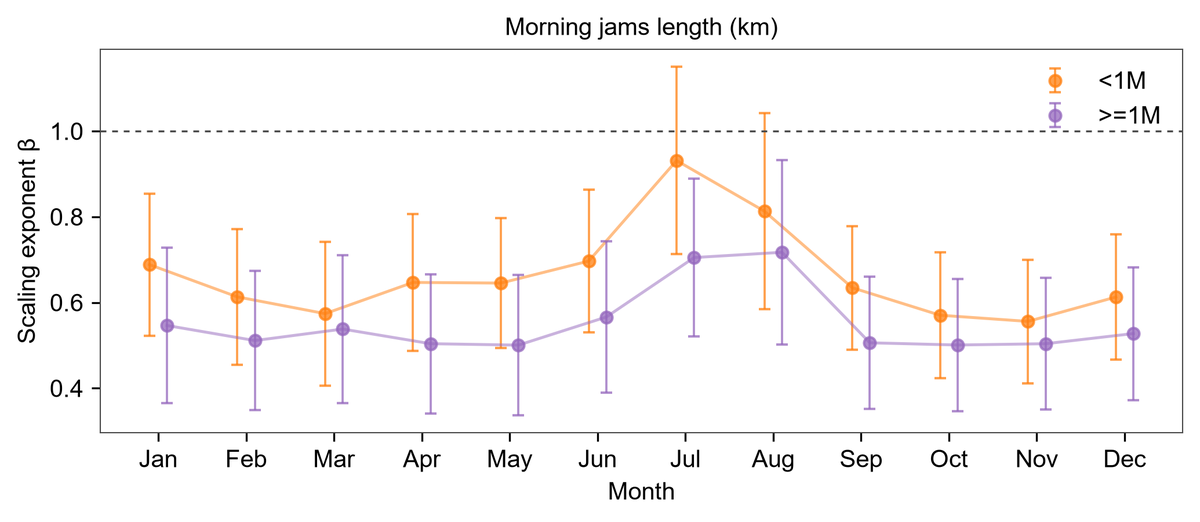

In [3]:
# Panel b: Morning monthly slopes
def monthly_peaks(data_dir, project_root, output_dir):

    output_dir.mkdir(parents=True, exist_ok=True)
    import os
    from pathlib import Path
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import statsmodels.api as sm

    FONT_FAMILY = "Arial"
    BASE_FS     = 10
    TITLE_FS    = 10
    LABEL_FS    = 10
    TICK_FS     = 10
    LEGEND_FS   = 10

    FIG_W = 14
    FIG_H = 6.2
    DPI   = 300

    COLOR_LT1M = "tab:orange"
    COLOR_GE1M = "tab:purple"
    REFLINE_COLOR = "#4A4A4A"
    SPINE_COLOR   = "#4A4A4A"

    GROUP_COLOR_MAP = {
        "<1M":  COLOR_LT1M,
        ">=1M": COLOR_GE1M
    }

    SPINE_LW     = 0.5
    LINE_LW      = 1.2
    LINE_ALPHA   = 0.50

    POINT_SIZE   = 4.8
    POINT_ALPHA  = 0.85

    ERRORBAR_LW  = 0.9
    ERROR_ALPHA  = 0.75
    CAPSIZE      = 2.5

    REF_LINE_Y      = 1.0
    REF_LINE_STYLE  = (0, (3, 3))
    REF_LINE_LW     = 0.8

    GROUP_OFFSET_MAP = {
        "<1M":  -0.10,
        ">=1M":  0.10
    }

    CI_ALPHA_LEVEL = 0.05
    POP_CUT = 1_000_000

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": BASE_FS,
        "axes.titlesize": TITLE_FS,
        "axes.labelsize": LABEL_FS,
        "xtick.labelsize": TICK_FS,
        "ytick.labelsize": TICK_FS,
        "legend.fontsize": LEGEND_FS,
    })

    DATA_DIR = Path(str(project_root / 'data/final_data'))
    OUT_DIR = output_dir
    OUT_DIR.mkdir(parents=True, exist_ok=True)

    FILE_MAP = {f"M{i}": i for i in range(1, 13)}

    X_COL = "population"
    CITY_COL = "city"
    COUNTRY_COL = "country"
    CONTINENT_COL = "continent"

    Y_COLS = ['morning_peak_congested_network_length']

    Y_LABEL_MAP = {
        "congested_network_length": "All-day jams length (km)",
        "NonPeak_JamsLengthInKms": "Non-peak jams length (km)",
        "morning_peak_congested_network_length": "Morning jams length (km)",
        "evening_peak_congested_network_length": "Evening jams length (km)"
    }

    GROUP_ORDER = ["<1M", ">=1M"]

    MONTH_ORDER = [f"M{i}" for i in range(1, 13)]
    MONTH_LABELS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

    monthly_data = pd.read_csv(data_dir / "city_monthly.csv")

    def load_and_clean(fp):
        df = monthly_data.loc[monthly_data["month"] == fp].copy()

        need_cols = [CITY_COL, COUNTRY_COL, CONTINENT_COL, X_COL] + Y_COLS
        exist_cols = [c for c in need_cols if c in df.columns]
        df = df[exist_cols].copy()

        missing_cols = [c for c in [X_COL] + Y_COLS if c not in df.columns]
        if missing_cols:
            raise ValueError(f"{fp} is missing columns: {missing_cols}")

        for c in [X_COL] + Y_COLS:
            df[c] = pd.to_numeric(df[c], errors="coerce")

        if CONTINENT_COL in df.columns:
            df[CONTINENT_COL] = df[CONTINENT_COL].astype(str).str.strip()

        df = df[df[X_COL] > 0].copy()
        return df

    def fit_loglog(d, x_col, y_col):
        sub = d.dropna(subset=[x_col, y_col]).copy()
        sub = sub[(sub[x_col] > 0) & (sub[y_col] > 0)].copy()

        if len(sub) < 3:
            return None

        x = np.log10(sub[x_col].values)
        y = np.log10(sub[y_col].values)

        X = sm.add_constant(x)
        model = sm.OLS(y, X).fit()

        beta = float(model.params[1])
        intercept = float(model.params[0])
        pval = float(model.pvalues[1])
        r2 = float(model.rsquared)
        n = int(model.nobs)

        ci = model.conf_int(alpha=CI_ALPHA_LEVEL)
        beta_ci_low = float(ci[1, 0])
        beta_ci_high = float(ci[1, 1])

        return {
            "n": n,
            "intercept": intercept,
            "beta": beta,
            "beta_ci_low": beta_ci_low,
            "beta_ci_high": beta_ci_high,
            "p": pval,
            "r2": r2,
            "model": model
        }

    def assign_group(population):
        return "<1M" if population < POP_CUT else ">=1M"

    results = []
    sample_count_rows = []

    for month in MONTH_ORDER:
        fp = FILE_MAP[month]
        df = load_and_clean(fp)

        df["pop_group"] = df[X_COL].apply(assign_group)

        grp_counts = (
            df.groupby("pop_group")
              .size()
              .reindex(GROUP_ORDER)
              .fillna(0)
              .astype(int)
        )
        for grp in GROUP_ORDER:
            sample_count_rows.append({
                "month": month,
                "group": grp,
                "n_cities": int(grp_counts.get(grp, 0))
            })

        for y_col in Y_COLS:
            for grp in GROUP_ORDER:
                sub = df[df["pop_group"] == grp].copy()
                res = fit_loglog(sub, X_COL, y_col)

                if res is None:
                    results.append({
                        "month": month,
                        "y_variable": y_col,
                        "group": grp,
                        "n": np.nan,
                        "beta": np.nan,
                        "beta_ci_low": np.nan,
                        "beta_ci_high": np.nan,
                        "p": np.nan,
                        "r2": np.nan
                    })
                else:
                    results.append({
                        "month": month,
                        "y_variable": y_col,
                        "group": grp,
                        "n": res["n"],
                        "beta": res["beta"],
                        "beta_ci_low": res["beta_ci_low"],
                        "beta_ci_high": res["beta_ci_high"],
                        "p": res["p"],
                        "r2": res["r2"]
                    })

    results_df = pd.DataFrame(results)
    sample_counts_df = pd.DataFrame(sample_count_rows)

    results_csv = OUT_DIR / "monthly_beta_by_pop_1m_split_jamslength.csv"
    results_df.to_csv(results_csv, index=False, encoding="utf-8-sig")

    sample_counts_csv = OUT_DIR / "monthly_city_counts_by_pop_1m_split.csv"
    sample_counts_df.to_csv(sample_counts_csv, index=False, encoding="utf-8-sig")

    print("\nMonthly beta estimates:")
    print(results_df.to_string(index=False))

    print("\nCity counts by month and group:")
    print(sample_counts_df.to_string(index=False))

    fig, axes = plt.subplots(
        1, 1,
        figsize=(FIG_W / 2, FIG_H / 2),
        dpi=DPI,
        sharex=True,
        sharey=False
    )
    axes = np.atleast_1d(axes).flatten()
    x_pos = np.arange(len(MONTH_ORDER))

    for ax, y_col in zip(axes, Y_COLS):
        panel_df = results_df[results_df["y_variable"] == y_col].copy()

        for grp in GROUP_ORDER:
            sub = panel_df[panel_df["group"] == grp].copy()
            sub["month"] = pd.Categorical(sub["month"], categories=MONTH_ORDER, ordered=True)
            sub = sub.sort_values("month")

            x_base = np.array([MONTH_ORDER.index(m) for m in sub["month"]], dtype=float)
            x = x_base + GROUP_OFFSET_MAP[grp]

            y = sub["beta"].values.astype(float)
            ci_low = sub["beta_ci_low"].values.astype(float)
            ci_high = sub["beta_ci_high"].values.astype(float)

            yerr_low = y - ci_low
            yerr_high = ci_high - y
            yerr = np.vstack([yerr_low, yerr_high])

            ax.plot(
                x, y,
                color=GROUP_COLOR_MAP[grp],
                linewidth=LINE_LW,
                alpha=LINE_ALPHA
            )

            ax.errorbar(
                x, y, yerr=yerr,
                fmt="o",
                linestyle="none",
                elinewidth=ERRORBAR_LW,
                capsize=CAPSIZE,
                markersize=POINT_SIZE,
                alpha=ERROR_ALPHA,
                color=GROUP_COLOR_MAP[grp],
                ecolor=GROUP_COLOR_MAP[grp],
                markerfacecolor=GROUP_COLOR_MAP[grp],
                markeredgecolor=GROUP_COLOR_MAP[grp],
                label=grp
            )

        ax.axhline(
            REF_LINE_Y,
            linestyle=REF_LINE_STYLE,
            linewidth=REF_LINE_LW,
            color=REFLINE_COLOR
        )

        ax.set_title(Y_LABEL_MAP.get(y_col, y_col), fontsize=TITLE_FS)
        ax.set_xlabel("Month", fontsize=LABEL_FS)
        ax.set_ylabel("Scaling exponent β", fontsize=LABEL_FS)

        ax.set_xticks(x_pos)
        ax.set_xticklabels(MONTH_LABELS, fontsize=TICK_FS)
        ax.tick_params(axis="y", labelsize=TICK_FS)

        for side in ["top", "right", "left", "bottom"]:
            ax.spines[side].set_visible(True)
            ax.spines[side].set_linewidth(SPINE_LW)
            ax.spines[side].set_color(SPINE_COLOR)

        ax.legend(fontsize=LEGEND_FS, frameon=False)

    plt.tight_layout()

    fig_png = OUT_DIR / "monthly_beta_change_by_pop_1m_split_jamslength_CI_connected_peak_panels.png"
    fig_pdf = OUT_DIR / "monthly_beta_change_by_pop_1m_split_jamslength_CI_connected_peak_panels.pdf"

    plt.savefig(fig_png, bbox_inches="tight")
    plt.savefig(fig_pdf, bbox_inches="tight")
    pass
    plt.close()

    for y_col in Y_COLS:
        tmp = results_df[results_df["y_variable"] == y_col].copy()
        out_csv = OUT_DIR / f"{y_col}_monthly_beta_by_pop_1m_split.csv"
        tmp.to_csv(out_csv, index=False, encoding="utf-8-sig")

    print("\n" + "=" * 100)
    print("Monthly plots saved (<1M / >=1M residents).")
    print(f"Output folder: {OUT_DIR}")
    print("\nSaved files:")
    print(results_csv)
    print(sample_counts_csv)
    print(fig_png)
    print(fig_pdf)
    for y_col in Y_COLS:
        print(OUT_DIR / f"{y_col}_monthly_beta_by_pop_1m_split.csv")

output_dir = OUTPUT_ROOT / "b"
with plt.rc_context():
    monthly_peaks(DATA_DIR, PROJECT_ROOT, output_dir)
plt.close("all")
show_saved(output_dir / 'monthly_beta_change_by_pop_1m_split_jamslength_CI_connected_peak_panels.png')


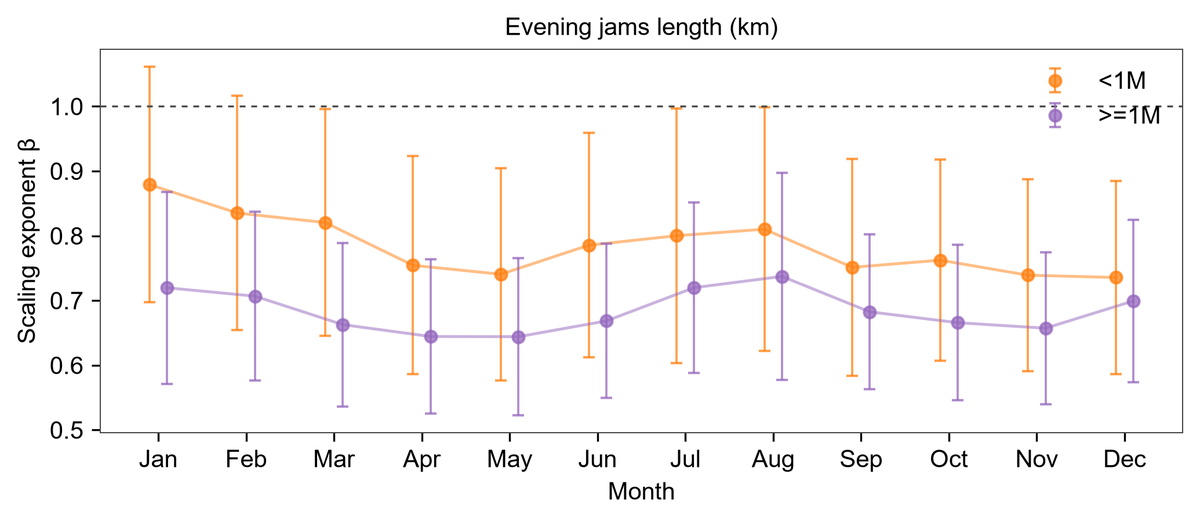

In [4]:
# Panel c: Evening monthly slopes
def monthly_peaks(data_dir, project_root, output_dir):

    output_dir.mkdir(parents=True, exist_ok=True)
    import os
    from pathlib import Path
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import statsmodels.api as sm

    FONT_FAMILY = "Arial"
    BASE_FS     = 10
    TITLE_FS    = 10
    LABEL_FS    = 10
    TICK_FS     = 10
    LEGEND_FS   = 10

    FIG_W = 14
    FIG_H = 6.2
    DPI   = 300

    COLOR_LT1M = "tab:orange"
    COLOR_GE1M = "tab:purple"
    REFLINE_COLOR = "#4A4A4A"
    SPINE_COLOR   = "#4A4A4A"

    GROUP_COLOR_MAP = {
        "<1M":  COLOR_LT1M,
        ">=1M": COLOR_GE1M
    }

    SPINE_LW     = 0.5
    LINE_LW      = 1.2
    LINE_ALPHA   = 0.50

    POINT_SIZE   = 4.8
    POINT_ALPHA  = 0.85

    ERRORBAR_LW  = 0.9
    ERROR_ALPHA  = 0.75
    CAPSIZE      = 2.5

    REF_LINE_Y      = 1.0
    REF_LINE_STYLE  = (0, (3, 3))
    REF_LINE_LW     = 0.8

    GROUP_OFFSET_MAP = {
        "<1M":  -0.10,
        ">=1M":  0.10
    }

    CI_ALPHA_LEVEL = 0.05
    POP_CUT = 1_000_000

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "font.size": BASE_FS,
        "axes.titlesize": TITLE_FS,
        "axes.labelsize": LABEL_FS,
        "xtick.labelsize": TICK_FS,
        "ytick.labelsize": TICK_FS,
        "legend.fontsize": LEGEND_FS,
    })

    DATA_DIR = Path(str(project_root / 'data/final_data'))
    OUT_DIR = output_dir
    OUT_DIR.mkdir(parents=True, exist_ok=True)

    FILE_MAP = {f"M{i}": i for i in range(1, 13)}

    X_COL = "population"
    CITY_COL = "city"
    COUNTRY_COL = "country"
    CONTINENT_COL = "continent"

    Y_COLS = ['evening_peak_congested_network_length']

    Y_LABEL_MAP = {
        "congested_network_length": "All-day jams length (km)",
        "NonPeak_JamsLengthInKms": "Non-peak jams length (km)",
        "morning_peak_congested_network_length": "Morning jams length (km)",
        "evening_peak_congested_network_length": "Evening jams length (km)"
    }

    GROUP_ORDER = ["<1M", ">=1M"]

    MONTH_ORDER = [f"M{i}" for i in range(1, 13)]
    MONTH_LABELS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

    monthly_data = pd.read_csv(data_dir / "city_monthly.csv")

    def load_and_clean(fp):
        df = monthly_data.loc[monthly_data["month"] == fp].copy()

        need_cols = [CITY_COL, COUNTRY_COL, CONTINENT_COL, X_COL] + Y_COLS
        exist_cols = [c for c in need_cols if c in df.columns]
        df = df[exist_cols].copy()

        missing_cols = [c for c in [X_COL] + Y_COLS if c not in df.columns]
        if missing_cols:
            raise ValueError(f"{fp} is missing columns: {missing_cols}")

        for c in [X_COL] + Y_COLS:
            df[c] = pd.to_numeric(df[c], errors="coerce")

        if CONTINENT_COL in df.columns:
            df[CONTINENT_COL] = df[CONTINENT_COL].astype(str).str.strip()

        df = df[df[X_COL] > 0].copy()
        return df

    def fit_loglog(d, x_col, y_col):
        sub = d.dropna(subset=[x_col, y_col]).copy()
        sub = sub[(sub[x_col] > 0) & (sub[y_col] > 0)].copy()

        if len(sub) < 3:
            return None

        x = np.log10(sub[x_col].values)
        y = np.log10(sub[y_col].values)

        X = sm.add_constant(x)
        model = sm.OLS(y, X).fit()

        beta = float(model.params[1])
        intercept = float(model.params[0])
        pval = float(model.pvalues[1])
        r2 = float(model.rsquared)
        n = int(model.nobs)

        ci = model.conf_int(alpha=CI_ALPHA_LEVEL)
        beta_ci_low = float(ci[1, 0])
        beta_ci_high = float(ci[1, 1])

        return {
            "n": n,
            "intercept": intercept,
            "beta": beta,
            "beta_ci_low": beta_ci_low,
            "beta_ci_high": beta_ci_high,
            "p": pval,
            "r2": r2,
            "model": model
        }

    def assign_group(population):
        return "<1M" if population < POP_CUT else ">=1M"

    results = []
    sample_count_rows = []

    for month in MONTH_ORDER:
        fp = FILE_MAP[month]
        df = load_and_clean(fp)

        df["pop_group"] = df[X_COL].apply(assign_group)

        grp_counts = (
            df.groupby("pop_group")
              .size()
              .reindex(GROUP_ORDER)
              .fillna(0)
              .astype(int)
        )
        for grp in GROUP_ORDER:
            sample_count_rows.append({
                "month": month,
                "group": grp,
                "n_cities": int(grp_counts.get(grp, 0))
            })

        for y_col in Y_COLS:
            for grp in GROUP_ORDER:
                sub = df[df["pop_group"] == grp].copy()
                res = fit_loglog(sub, X_COL, y_col)

                if res is None:
                    results.append({
                        "month": month,
                        "y_variable": y_col,
                        "group": grp,
                        "n": np.nan,
                        "beta": np.nan,
                        "beta_ci_low": np.nan,
                        "beta_ci_high": np.nan,
                        "p": np.nan,
                        "r2": np.nan
                    })
                else:
                    results.append({
                        "month": month,
                        "y_variable": y_col,
                        "group": grp,
                        "n": res["n"],
                        "beta": res["beta"],
                        "beta_ci_low": res["beta_ci_low"],
                        "beta_ci_high": res["beta_ci_high"],
                        "p": res["p"],
                        "r2": res["r2"]
                    })

    results_df = pd.DataFrame(results)
    sample_counts_df = pd.DataFrame(sample_count_rows)

    results_csv = OUT_DIR / "monthly_beta_by_pop_1m_split_jamslength.csv"
    results_df.to_csv(results_csv, index=False, encoding="utf-8-sig")

    sample_counts_csv = OUT_DIR / "monthly_city_counts_by_pop_1m_split.csv"
    sample_counts_df.to_csv(sample_counts_csv, index=False, encoding="utf-8-sig")

    print("\nMonthly beta estimates:")
    print(results_df.to_string(index=False))

    print("\nCity counts by month and group:")
    print(sample_counts_df.to_string(index=False))

    fig, axes = plt.subplots(
        1, 1,
        figsize=(FIG_W / 2, FIG_H / 2),
        dpi=DPI,
        sharex=True,
        sharey=False
    )
    axes = np.atleast_1d(axes).flatten()
    x_pos = np.arange(len(MONTH_ORDER))

    for ax, y_col in zip(axes, Y_COLS):
        panel_df = results_df[results_df["y_variable"] == y_col].copy()

        for grp in GROUP_ORDER:
            sub = panel_df[panel_df["group"] == grp].copy()
            sub["month"] = pd.Categorical(sub["month"], categories=MONTH_ORDER, ordered=True)
            sub = sub.sort_values("month")

            x_base = np.array([MONTH_ORDER.index(m) for m in sub["month"]], dtype=float)
            x = x_base + GROUP_OFFSET_MAP[grp]

            y = sub["beta"].values.astype(float)
            ci_low = sub["beta_ci_low"].values.astype(float)
            ci_high = sub["beta_ci_high"].values.astype(float)

            yerr_low = y - ci_low
            yerr_high = ci_high - y
            yerr = np.vstack([yerr_low, yerr_high])

            ax.plot(
                x, y,
                color=GROUP_COLOR_MAP[grp],
                linewidth=LINE_LW,
                alpha=LINE_ALPHA
            )

            ax.errorbar(
                x, y, yerr=yerr,
                fmt="o",
                linestyle="none",
                elinewidth=ERRORBAR_LW,
                capsize=CAPSIZE,
                markersize=POINT_SIZE,
                alpha=ERROR_ALPHA,
                color=GROUP_COLOR_MAP[grp],
                ecolor=GROUP_COLOR_MAP[grp],
                markerfacecolor=GROUP_COLOR_MAP[grp],
                markeredgecolor=GROUP_COLOR_MAP[grp],
                label=grp
            )

        ax.axhline(
            REF_LINE_Y,
            linestyle=REF_LINE_STYLE,
            linewidth=REF_LINE_LW,
            color=REFLINE_COLOR
        )

        ax.set_title(Y_LABEL_MAP.get(y_col, y_col), fontsize=TITLE_FS)
        ax.set_xlabel("Month", fontsize=LABEL_FS)
        ax.set_ylabel("Scaling exponent β", fontsize=LABEL_FS)

        ax.set_xticks(x_pos)
        ax.set_xticklabels(MONTH_LABELS, fontsize=TICK_FS)
        ax.tick_params(axis="y", labelsize=TICK_FS)

        for side in ["top", "right", "left", "bottom"]:
            ax.spines[side].set_visible(True)
            ax.spines[side].set_linewidth(SPINE_LW)
            ax.spines[side].set_color(SPINE_COLOR)

        ax.legend(fontsize=LEGEND_FS, frameon=False)

    plt.tight_layout()

    fig_png = OUT_DIR / "monthly_beta_change_by_pop_1m_split_jamslength_CI_connected_peak_panels.png"
    fig_pdf = OUT_DIR / "monthly_beta_change_by_pop_1m_split_jamslength_CI_connected_peak_panels.pdf"

    plt.savefig(fig_png, bbox_inches="tight")
    plt.savefig(fig_pdf, bbox_inches="tight")
    pass
    plt.close()

    for y_col in Y_COLS:
        tmp = results_df[results_df["y_variable"] == y_col].copy()
        out_csv = OUT_DIR / f"{y_col}_monthly_beta_by_pop_1m_split.csv"
        tmp.to_csv(out_csv, index=False, encoding="utf-8-sig")

    print("\n" + "=" * 100)
    print("Monthly plots saved (<1M / >=1M residents).")
    print(f"Output folder: {OUT_DIR}")
    print("\nSaved files:")
    print(results_csv)
    print(sample_counts_csv)
    print(fig_png)
    print(fig_pdf)
    for y_col in Y_COLS:
        print(OUT_DIR / f"{y_col}_monthly_beta_by_pop_1m_split.csv")

output_dir = OUTPUT_ROOT / "c"
with plt.rc_context():
    monthly_peaks(DATA_DIR, PROJECT_ROOT, output_dir)
plt.close("all")
show_saved(output_dir / 'monthly_beta_change_by_pop_1m_split_jamslength_CI_connected_peak_panels.png')
